In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
import seaborn as sns
from os import listdir

In [3]:
DATA_PATH = '/Users/euanprentis/Documents/feat-predict_simulations/exp-3/data/exp_2'
RESULTS_PATH = '../results/exp_2'
FIG_PATH = '../figs'
MODELS = ['ss', 'ss-sampler', 'ff']
MODELS_FIT = ['ss', 'ss-sampler', 'ff', 'null']
MODEL_LABELS = {
    'ss': 'Conj.',
    'ss-sampler': 'Conj.\nSampler',
    'ff': 'Feat.',
    'null': 'Null'
}

PARAM_LABELS = {
    'alpha': r'$\it{α}$',
    'beta': r'$\it{β}$',
    'beta_trans': r'log($\it{β}$)',
    'lmbd': r'$\it{λ}$',
    'lmbd_l1': r'$\it{λ}_{\mathregular{L1}}$',
    'lmbd_l1_trans': r'log($\it{λ}_{\mathregular{L1}}$)',
    'bias_magnitude': r'$\it{b}$',
    'inference_power': r'$\it{κ}$',
    'inference_power_trans': r'log($\it{κ}$)',
    'sampler_feature_weight': r'$\it{ω}^{SIM}$',
    'sampler_specificity':  r'$\it{Ψ}$'
}


DEFAULT_VALUES = {
    'alpha': 1,
    'beta': 1,
    'lmbd': 0,
    'lmbd_l1': 0,
    'bias_magnitude': 0,
    'inference_power': 1,
    'sampler_feature_weight': 0.5,
    'sampler_specificity': 1
}

COMPARISON_PARAMETERS = [
    'alpha',
    'beta',
    'lmbd',
    'lmbd_l1',
    'bias_magnitude',
    'inference_power',
    'sampler_feature_weight',
    'sampler_specificity'
]
SF_MB_MODEL_COLORS = {
    'sf': '#D65EB0',
    'mb': '#C0E88F'
}

SF_MODEL_COLORS = {
    'sf-ff-bias': '#D65EB0',
    'sf-ff-decay': "#776b8c",
    'sf-ff-l1reg': "#af9cd0",
    'sf-ff-nonlin': "#b382a0",
    #'null': 'grey'
} 

# Model colors
MODEL_COLORS = {
    'ss': '#9cd8ff',
    'ss-sampler': '#3DB2FF',
    'ff': '#FF2442',
    'null': 'grey'
}
MODEL_COLORS = {k: MODEL_COLORS[k] for k in MODELS_FIT}
MODEL_FIT_LABELS = {k: MODEL_LABELS[k] for k in MODELS_FIT}
MODEL_LABELS = {k: MODEL_LABELS[k] for k in MODELS}


# Functions

In [4]:
def set_axis_ratio(ax, ratio=1):
    """
    Make axis aspect ratio square
    
    Arguments
    ---------
    ax : matplotlib.Axes
        matplotlib axis to transform
    ratio : int or float
        ratio of y- to x-axis
        
    Returns
    -------
    None
    """
    ax.set_aspect(ratio/ax.get_data_ratio(), adjustable='box')

def round_up(x, n):
    """
    Round up to n decimal places

    Arguments
    ---------
    x : int or float
        input value
    n : int
        number of decimal places
    
    Returns
    -------
    float
        x rounded up to n decimal
    """
    factor = 10**n
    return np.ceil(x*factor)/factor


def plot_parameter_relationship(
    df,
    x,
    y,
    x_label = None,
    y_label = None,
    color = None,
    fname = False,
    logistic = True
):
    """
    Plot relationship between two parameters

    Arguments
    ---------
    df : pandas.DataFrame
        data frame containing parameters
    x : str
        column name for x-axis
    y : str
        column name for y-axis
    x_label : str
        label for x-axis
    y_label : str
        label for y-axis
    color : str
        color for plot
    fname : str or bool
        file name to save plot, if False do not save
    
    Returns
    -------
    None
    """

    # Init JointGrid
    g = sns.JointGrid(data=df, x=x, y=y, height=1.75)

    # Plot Logistic
    sns.regplot(
        data = df,
        x = x,
        y = y,
        logistic = logistic,
        color = color,
        scatter_kws = {'s': 1},
        line_kws = {'color': 'black'},
        ax = g.ax_joint,
    )

    # Plot histograms on the marginal axes
    g.plot_marginals(
        sns.histplot,
        color = color
    )
    g.set_axis_labels(x_label, y_label)

    # Save figure if fname is provided
    if fname:
        plt.savefig(fname, bbox_inches='tight')

    # Print Pearson's and Spearman's correlations
    pear_val, pear_p = pearsonr(df[x], df[y])
    spear_val, spear_p = spearmanr(df[x], df[y])
    print(f"""
    {x} vs {y}
    Pearson's correlation: {np.round(pear_val, 2)} (p <= {round_up(pear_p, 4)})
    Spearman's correlation: {np.round(spear_val, 2)} (p <= {round_up(spear_p, 4)})
    """)


# Load Data
## Load Simulated Parameters

In [5]:
def load_simulation_information(data_path, default_values=None):

    # Load simulation parameters from raw data into one data frame
    sim_params = []
    for model_class in listdir(data_path):
        if '.' in model_class: continue
        for sim_model in listdir(f'{data_path}/{model_class}'):
            if '.' in sim_model: continue
            dpath = f'{data_path}/{model_class}/{sim_model}/training'
            for fname in listdir(dpath):
                if '.csv' not in fname: continue
                
                # Load parameter information for agent
                df = pd.read_csv( f'{dpath}/{fname}')
                df = df.drop(columns=[
                    'model', 'trial', 'target_comb', 'options_comb', 'target',
                    'options', 'steps_from_terminal', 'composition',
                    'successor', 'p', 'reward', 'correct'
                ]).drop_duplicates()
                sim_params.append(df)
    sim_params = pd.concat(sim_params, ignore_index=True)

    # For params of interest, replace missing values with defaults
    if default_values is not None:
        for param, default in default_values.items():
            sim_params[param] = sim_params[param].fillna(default)
        sim_params = sim_params[['id', 'model_label', *default_values.keys()]]

    # Rename model_label to model_label_sim
    sim_params = sim_params.rename(columns={'model_label': 'model_label_sim'})

    return sim_params


In [6]:
sim_params = load_simulation_information(
    DATA_PATH,
    default_values = DEFAULT_VALUES
    )

sim_params

,id,model_label_sim,alpha,beta,lmbd,lmbd_l1,bias_magnitude,inference_power,sampler_feature_weight,sampler_specificity
0,388,mb-ss,0.335038,0.983618,0.0,0.0,0.0,1.0,0.5,1.0
1,363,mb-ss,0.105407,0.408229,0.0,0.0,0.0,1.0,0.5,1.0
2,405,mb-ss,0.701583,2.593581,0.0,0.0,0.0,1.0,0.5,1.0
3,411,mb-ss,0.845361,0.615863,0.0,0.0,0.0,1.0,0.5,1.0
4,377,mb-ss,0.118484,0.919574,0.0,0.0,0.0,1.0,0.5,1.0
...,...,...,...,...,...,...,...,...,...,...
13995,420,sf-ss,0.315646,1.207356,0.0,0.0,0.0,1.0,0.5,1.0
13996,346,sf-ss,0.593620,108.862889,0.0,0.0,0.0,1.0,0.5,1.0
13997,408,sf-ss,0.493644,0.201781,0.0,0.0,0.0,1.0,0.5,1.0
13998,391,sf-ss,0.058556,7.011046,0.0,0.0,0.0,1.0,0.5,1.0


## Load Fitting Results

In [7]:
def load_model_fits(results_path, default_values=None):

    # Load model fits into one data frame
    model_fits = []
    for model_class in listdir(results_path):
        if '.' in model_class: continue
        for sim_model in listdir(f'{results_path}/{model_class}'):
            if '.' in sim_model: continue
            this_model_fits = pd.read_csv(
                f'{results_path}/{model_class}/{sim_model}'
                '/model_fits.csv',
                na_values = ['', 'NaN', None],
                keep_default_na = False
                )
            this_model_fits['model_label_sim'] = sim_model
            model_fits.append(this_model_fits)
            
    model_fits = pd.concat(model_fits, ignore_index=True)

     # For params of interest, replace missing values with defaults
    if default_values is not None:
        for param, default in default_values.items():
            model_fits[param] = model_fits[param].fillna(default)
            model_fits = model_fits[[
                'id',
                'model_label_sim',
                'model_label',
                'aic',
                *default_values.keys()
                ]]

    # Rename model_label to model_label_fit
    model_fits = model_fits.rename(columns={'model_label': 'model_label_fit'})

    return model_fits



In [8]:
model_fits = load_model_fits(
    RESULTS_PATH,
    default_values = DEFAULT_VALUES
    )

model_fits

,id,model_label_sim,model_label_fit,aic,alpha,beta,lmbd,lmbd_l1,bias_magnitude,inference_power,sampler_feature_weight,sampler_specificity
0,1,mb-ss,mb-ff,843.945680,0.238875,0.037530,0.000000,0.0,0.0,1.000000,0.500000,1.000000
1,1,mb-ss,mb-ff-bias,845.537554,0.550767,0.076004,0.000000,0.0,1.0,1.000000,0.500000,1.000000
2,1,mb-ss,mb-ss,838.919637,0.148325,0.669082,0.000000,0.0,0.0,1.000000,0.500000,1.000000
3,1,mb-ss,mb-ss-sampler,845.427359,1.000000,0.256085,0.000000,0.0,0.0,1.000000,0.971507,229.326694
4,1,mb-ss,null,840.094383,-1.000000,-1.000000,0.000000,-1.0,0.0,1.000000,0.500000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
209995,1000,sf-ss,sf-ff-decay,685.933719,0.357432,7.208538,0.479521,0.0,0.0,1.000000,0.500000,1.000000
209996,1000,sf-ss,sf-ff-l1reg,688.030924,0.559425,3.114968,0.000000,0.0,0.0,1.000000,0.500000,1.000000
209997,1000,sf-ss,sf-ff-nonlin,682.763553,0.517535,3.218219,0.000000,0.0,0.0,0.352026,0.500000,1.000000
209998,1000,sf-ss,sf-ss,506.640746,0.567154,8.969839,0.000000,0.0,0.0,1.000000,0.500000,1.000000


## Combine into one data frame

In [9]:
# Marge simulated and fit parameters
model_fits = pd.merge(
    sim_params,
    model_fits,
    on = ['id', 'model_label_sim'],
    suffixes = ('_sim', '_fit')
)

# # Transform betas to be bounded [0, 1]
for param in COMPARISON_PARAMETERS:
    if param in ['beta', 'sampler_specificity', 'inference_power', 'lmbd_l1']:
        model_fits[f'{param}_trans_sim'] = np.log(model_fits[f'{param}_sim'])
        model_fits[f'{param}_trans_fit'] = np.log(model_fits[f'{param}_fit'])

        idx = (
            np.isnan(model_fits[f'{param}_trans_sim']) |
            np.isinf(model_fits[f'{param}_trans_sim'])
            )
        model_fits.loc[idx, f'{param}_trans_sim'] = 0

        idx = (
            np.isnan(model_fits[f'{param}_trans_fit']) |
            np.isinf(model_fits[f'{param}_trans_fit'])
            )
        model_fits.loc[idx, f'{param}_trans_fit'] = 0
        
model_fits

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc,

,id,model_label_sim,alpha_sim,beta_sim,lmbd_sim,lmbd_l1_sim,bias_magnitude_sim,inference_power_sim,sampler_feature_weight_sim,sampler_specificity_sim,...,sampler_feature_weight_fit,sampler_specificity_fit,beta_trans_sim,beta_trans_fit,lmbd_l1_trans_sim,lmbd_l1_trans_fit,inference_power_trans_sim,inference_power_trans_fit,sampler_specificity_trans_sim,sampler_specificity_trans_fit
0,388,mb-ss,0.335038,0.983618,0.0,0.0,0.0,1.0,0.5,1.0,...,0.500000,1.000000,-0.016517,0.120580,0.0,0.00000,0.0,0.000000,0.0,0.000000
1,388,mb-ss,0.335038,0.983618,0.0,0.0,0.0,1.0,0.5,1.0,...,0.500000,1.000000,-0.016517,0.120573,0.0,0.00000,0.0,0.000000,0.0,0.000000
2,388,mb-ss,0.335038,0.983618,0.0,0.0,0.0,1.0,0.5,1.0,...,0.500000,1.000000,-0.016517,-0.081335,0.0,0.00000,0.0,0.000000,0.0,0.000000
3,388,mb-ss,0.335038,0.983618,0.0,0.0,0.0,1.0,0.5,1.0,...,0.455154,60.366313,-0.016517,-0.189145,0.0,0.00000,0.0,0.000000,0.0,4.100431
4,388,mb-ss,0.335038,0.983618,0.0,0.0,0.0,1.0,0.5,1.0,...,0.500000,1.000000,-0.016517,0.000000,0.0,0.00000,0.0,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209995,385,sf-ss,0.083025,4.066538,0.0,0.0,0.0,1.0,0.5,1.0,...,0.500000,1.000000,1.402792,0.281860,0.0,0.00000,0.0,0.000000,0.0,0.000000
209996,385,sf-ss,0.083025,4.066538,0.0,0.0,0.0,1.0,0.5,1.0,...,0.500000,1.000000,1.402792,-0.449286,0.0,-1.94591,0.0,0.000000,0.0,0.000000
209997,385,sf-ss,0.083025,4.066538,0.0,0.0,0.0,1.0,0.5,1.0,...,0.500000,1.000000,1.402792,-0.602703,0.0,0.00000,0.0,0.920489,0.0,0.000000
209998,385,sf-ss,0.083025,4.066538,0.0,0.0,0.0,1.0,0.5,1.0,...,0.500000,1.000000,1.402792,1.693952,0.0,0.00000,0.0,0.000000,0.0,0.000000


# Model Recovery

## Compute if the best fitting model matches the simulated model

In [10]:
def compare_models(all_fits, params=[]):

    comparisons = all_fits[[
        'id',
        'model_label_sim',
        'model_label_fit',
        'aic',
        *params
    ]]

    # Compute the minimum AIC for each agent
    min_aic = comparisons[['id', 'model_label_sim', 'aic', *params]]
    min_aic = min_aic.groupby(['id', 'model_label_sim', *params]).min()
    min_aic = min_aic.reset_index()
    comparisons = pd.merge(
        comparisons,
        min_aic,
        on = ['id', 'model_label_sim', *params],
        suffixes = ('', '_min')
    )

    # Identify the model with the lowest AIC as the best fit
    comparisons['best_fit'] = (comparisons['aic'] == comparisons['aic_min'])
    comparisons['best_fit'] = comparisons['best_fit'].astype(int)

    # Get best fitting models only
    best = comparisons[comparisons['best_fit'] == 1]
    best = best.reset_index(drop=True) 

    # Model is recovered if the best fit model matches the simulated model
    best['recovered'] = (
        (best['model_label_sim'] == best['model_label_fit']) &
        (best['best_fit'] == 1)
    ).astype(int)

    return comparisons, best

In [11]:
# Run model comparison within successor features models
moi = ['sf-ff-bias', 'sf-ss', 'sf-ss-sampler']
idx = (
    model_fits['model_label_sim'].isin(moi) &
    model_fits['model_label_fit'].isin([*moi, 'null'])
)
model_comparison, best_fits = compare_models(model_fits.loc[idx])

# Simplified labels for plotting
model_comparison = model_comparison.replace({
    'sf-ff-bias': 'ff',
    'sf-ss': 'ss',
    'sf-ss-sampler': 'ss-sampler'
    })

# Simplified labels for plotting
best_fits = best_fits.replace({
    'sf-ff-bias': 'ff',
    'sf-ss': 'ss',
    'sf-ss-sampler': 'ss-sampler'
    })

best_fits

,id,model_label_sim,model_label_fit,aic,aic_min,best_fit,recovered
0,388,ss-sampler,ss-sampler,877.812982,877.812982,1,1
1,363,ss-sampler,ss-sampler,526.705572,526.705572,1,1
2,405,ss-sampler,ss-sampler,879.623049,879.623049,1,1
3,411,ss-sampler,null,881.683214,881.683214,1,0
4,377,ss-sampler,null,881.683214,881.683214,1,0
...,...,...,...,...,...,...,...
2995,420,ss,ss,858.986915,858.986915,1,1
2996,346,ss,ss,440.489117,440.489117,1,1
2997,408,ss,null,881.683214,881.683214,1,0
2998,391,ss,ss,834.705005,834.705005,1,1


## Plot model recovery rates

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_5343/1500827767.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(MODEL_LABELS.values())


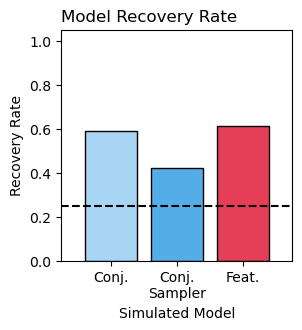

In [13]:
fig, ax = plt.subplots(figsize=(3, 3))
sns.barplot(
    data = best_fits,
    x = 'model_label_sim',
    y = 'recovered',
    order = MODELS,
    ci = None,
    palette = MODEL_COLORS,
    edgecolor = 'black'
)
ax.axhline(1/len(MODELS_FIT), color='black', linestyle='--')
ax.set_xlabel('Simulated Model')
ax.set_ylabel('Recovery Rate')
ax.set_xlim(-0.75, 2.75)
ax.set_ylim(0, 1.05)
ax.set_title('Model Recovery Rate', loc='left')
ax.set_xticklabels(MODEL_LABELS.values())
set_axis_ratio(ax)

## Fit rates for each model

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_5343/3512919295.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(MODEL_LABELS.values())


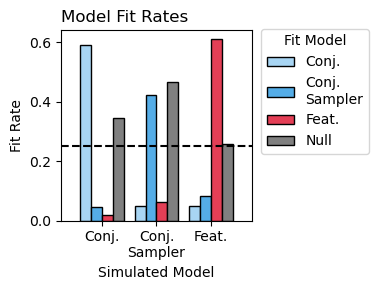

In [14]:
# 1. Compute exact within-group fractions
# Group by the x-axis category AND the hue category
counts_df = (
    best_fits.groupby(['model_label_sim', 'model_label_fit'])
    .size()
    .reset_index(name='count')
)

# Divide each fit count by the total number of simulations for that specific x-axis model
counts_df['fit_rate'] = counts_df['count'] / counts_df.groupby('model_label_sim')['count'].transform('sum')


# 2. Plot using standard barplot
fig, ax = plt.subplots(figsize=(4, 3))

sns.barplot(
    data = counts_df,
    x = 'model_label_sim',
    y = 'fit_rate', 
    order = MODELS,
    hue = 'model_label_fit',
    hue_order = MODELS_FIT,
    palette = MODEL_COLORS,
    edgecolor = 'black',
    ax = ax
)

# 3. Apply your custom styling elements
ax.axhline(1/(len(MODELS) + 1), color='black', linestyle='--')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, MODEL_FIT_LABELS.values(), title='Fit Model', loc=(1.05, .35))
ax.set_xlabel('Simulated Model')
ax.set_ylabel('Fit Rate')
ax.set_xlim(-0.75, 2.75)
ax.set_title('Model Fit Rates', loc='left')
ax.set_xticklabels(MODEL_LABELS.values())

set_axis_ratio(ax)
fig.tight_layout()

# Parameter Recovery

## Feature-Based Model (SF)

### Learning Rate Recovery

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_sim vs alpha_fit
    Pearson's correlation: 0.55 (p <= 0.0001)
    Spearman's correlation: 0.53 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_sim vs beta_trans_fit
    Pearson's correlation: -0.04 (p <= 0.1552)
    Spearman's correlation: -0.04 (p <= 0.1868)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_sim vs bias_magnitude_fit
    Pearson's correlation: 0.0 (p <= 0.9678)
    Spearman's correlation: 0.01 (p <= 0.7674)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_fit vs beta_trans_fit
    Pearson's correlation: -0.3 (p <= 0.0001)
    Spearman's correlation: -0.37 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_fit vs bias_magnitude_fit
    Pearson's correlation: 0.0 (p <= 0.9535)
    Spearman's correlation: 0.02 (p <= 0.5507)
    


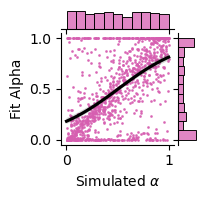

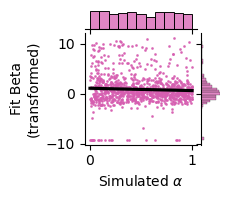

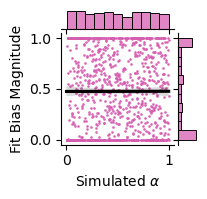

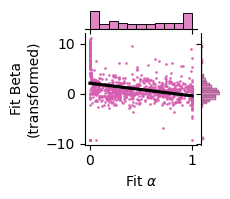

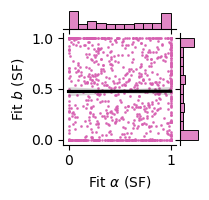

In [12]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias') &
    (model_fits['model_label_fit'] == 'sf-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_sim',
    'alpha_fit',
    x_label = f'Simulated {PARAM_LABELS["alpha"]}',
    y_label = 'Fit Alpha',
    color = SF_MB_MODEL_COLORS['sf']
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_sim',
    'beta_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["alpha"]}',
    y_label = 'Fit Beta\n(transformed)',
    color = SF_MB_MODEL_COLORS['sf'],
    logistic = False
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["alpha"]}',
    y_label = 'Fit Bias Magnitude',
    color = SF_MB_MODEL_COLORS['sf']
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_fit',
    'beta_trans_fit',
    x_label = f'Fit {PARAM_LABELS["alpha"]}',
    y_label = 'Fit Beta\n(transformed)',
    color = SF_MB_MODEL_COLORS['sf'],
    logistic = False
    
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_fit',
    'bias_magnitude_fit',
    x_label = f'Fit {PARAM_LABELS["alpha"]} (SF)',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]} (SF)',
    color = SF_MB_MODEL_COLORS['sf'],
    fname = f'{FIG_PATH}/sf-ff-alpha-fit-vs-bias-fit.pdf'
)


### Inverse Temperature Recovery

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    beta_trans_sim vs beta_trans_fit
    Pearson's correlation: 0.35 (p <= 0.0001)
    Spearman's correlation: 0.57 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    beta_trans_sim vs bias_magnitude_fit
    Pearson's correlation: 0.07 (p <= 0.0289)
    Spearman's correlation: 0.08 (p <= 0.0138)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    beta_trans_fit vs bias_magnitude_fit
    Pearson's correlation: 0.01 (p <= 0.7124)
    Spearman's correlation: -0.02 (p <= 0.575)
    


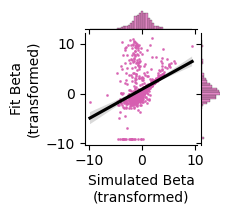

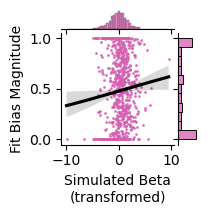

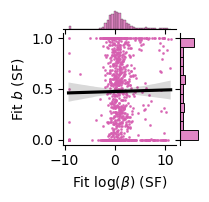

In [13]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias') &
    (model_fits['model_label_fit'] == 'sf-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'beta_trans_sim',
    'beta_trans_fit',
    x_label = 'Simulated Beta\n(transformed)',
    y_label = 'Fit Beta\n(transformed)',
    color = SF_MB_MODEL_COLORS['sf'],
    logistic = False
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'beta_trans_sim',
    'bias_magnitude_fit',
    x_label = 'Simulated Beta\n(transformed)',
    y_label = 'Fit Bias Magnitude',
    color = SF_MB_MODEL_COLORS['sf'],
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'beta_trans_fit',
    'bias_magnitude_fit',
    x_label = f'Fit {PARAM_LABELS["beta_trans"]} (SF)',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]} (SF)',
    color = SF_MB_MODEL_COLORS['sf'],
    fname = f'{FIG_PATH}/sf-ff-beta-fit-vs-bias-fit.pdf'
)


### Segmentation Recovery

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.4 (p <= 0.0001)
    Spearman's correlation: 0.37 (p <= 0.0001)
    


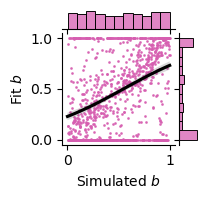

In [30]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias') &
    (model_fits['model_label_fit'] == 'sf-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = SF_MB_MODEL_COLORS['sf'],
    fname = f'{FIG_PATH}/sf-ff-bias-sim-vs-bias-fit.pdf'
)

## Feature-Based Model (MB)

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_sim vs alpha_fit
    Pearson's correlation: 0.58 (p <= 0.0001)
    Spearman's correlation: 0.56 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_sim vs beta_trans_fit
    Pearson's correlation: -0.01 (p <= 0.8715)
    Spearman's correlation: -0.02 (p <= 0.4308)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_sim vs bias_magnitude_fit
    Pearson's correlation: -0.03 (p <= 0.2789)
    Spearman's correlation: -0.03 (p <= 0.3618)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_fit vs beta_trans_fit
    Pearson's correlation: -0.12 (p <= 0.0002)
    Spearman's correlation: -0.24 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    alpha_fit vs bias_magnitude_fit
    Pearson's correlation: -0.01 (p <= 0.6985)
    Spearman's correlation: -0.01 (p <= 0.6952)
    


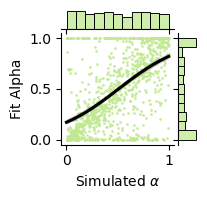

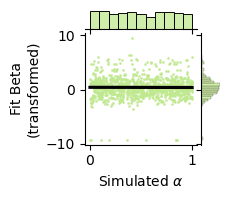

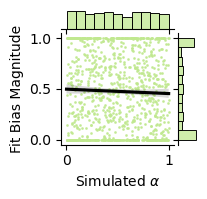

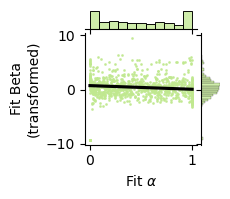

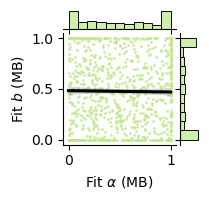

In [31]:
idx = (
    (model_fits['model_label_sim'] == 'mb-ff-bias') &
    (model_fits['model_label_fit'] == 'mb-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_sim',
    'alpha_fit',
    x_label = f'Simulated {PARAM_LABELS["alpha"]}',
    y_label = 'Fit Alpha',
    color = SF_MB_MODEL_COLORS['mb']
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_sim',
    'beta_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["alpha"]}',
    y_label = 'Fit Beta\n(transformed)',
    color = SF_MB_MODEL_COLORS['mb'],
    logistic = False
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["alpha"]}',
    y_label = 'Fit Bias Magnitude',
    color = SF_MB_MODEL_COLORS['mb'],
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_fit',
    'beta_trans_fit',
    x_label = f'Fit {PARAM_LABELS["alpha"]}',
    y_label = 'Fit Beta\n(transformed)',
    color = SF_MB_MODEL_COLORS['mb'],
    logistic = False
    
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'alpha_fit',
    'bias_magnitude_fit',
    x_label = f'Fit {PARAM_LABELS["alpha"]} (MB)',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]} (MB)',
    color = SF_MB_MODEL_COLORS['mb'],
    fname = f'{FIG_PATH}/mb-ff-alpha-fit-vs-bias-fit.pdf'
)


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    beta_trans_sim vs beta_trans_fit
    Pearson's correlation: 0.7 (p <= 0.0001)
    Spearman's correlation: 0.75 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    beta_trans_sim vs bias_magnitude_fit
    Pearson's correlation: 0.06 (p <= 0.0564)
    Spearman's correlation: 0.08 (p <= 0.0161)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    beta_trans_fit vs bias_magnitude_fit
    Pearson's correlation: 0.1 (p <= 0.001)
    Spearman's correlation: 0.14 (p <= 0.0001)
    


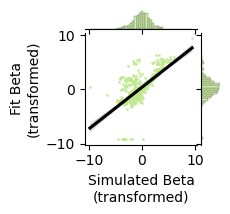

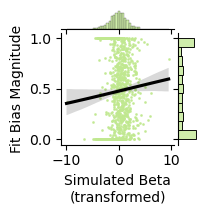

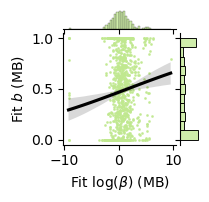

In [14]:
idx = (
    (model_fits['model_label_sim'] == 'mb-ff-bias') &
    (model_fits['model_label_fit'] == 'mb-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'beta_trans_sim',
    'beta_trans_fit',
    x_label = 'Simulated Beta\n(transformed)',
    y_label = 'Fit Beta\n(transformed)',
    color = SF_MB_MODEL_COLORS['mb'],
    logistic = False
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'beta_trans_sim',
    'bias_magnitude_fit',
    x_label = 'Simulated Beta\n(transformed)',
    y_label = 'Fit Bias Magnitude',
    color = SF_MB_MODEL_COLORS['mb'],
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'beta_trans_fit',
    'bias_magnitude_fit',
    x_label = f'Fit {PARAM_LABELS["beta_trans"]} (MB)',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]} (MB)',
    color = SF_MB_MODEL_COLORS['mb'],
    fname = f'{FIG_PATH}/mb-ff-beta-fit-vs-bias-fit.pdf'
)


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.51 (p <= 0.0001)
    Spearman's correlation: 0.48 (p <= 0.0001)
    


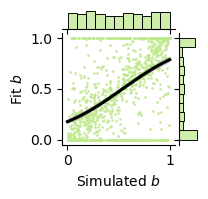

In [16]:
idx = (
    (model_fits['model_label_sim'] == 'mb-ff-bias') &
    (model_fits['model_label_fit'] == 'mb-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = SF_MB_MODEL_COLORS['mb'],
    fname = f'{FIG_PATH}/mb-ff-bias-sim-vs-bias-fit.pdf'
)

In [35]:

MODEL_LABELS = {
    'sf-ff-bias': f'Feature ({PARAM_LABELS["bias_magnitude"]})',
    'sf-ff-decay': f'Feature ({PARAM_LABELS["lmbd"]})',
    'sf-ff-l1reg': f'Feature ({PARAM_LABELS["lmbd_l1"]})',
    'sf-ff-nonlin': f'Feature ({PARAM_LABELS["inference_power"]})',
    #'null': 'Null'
}


MODEL_LEGLABELS = [v.replace('\n', ' ')  for v in MODEL_LABELS.values()]

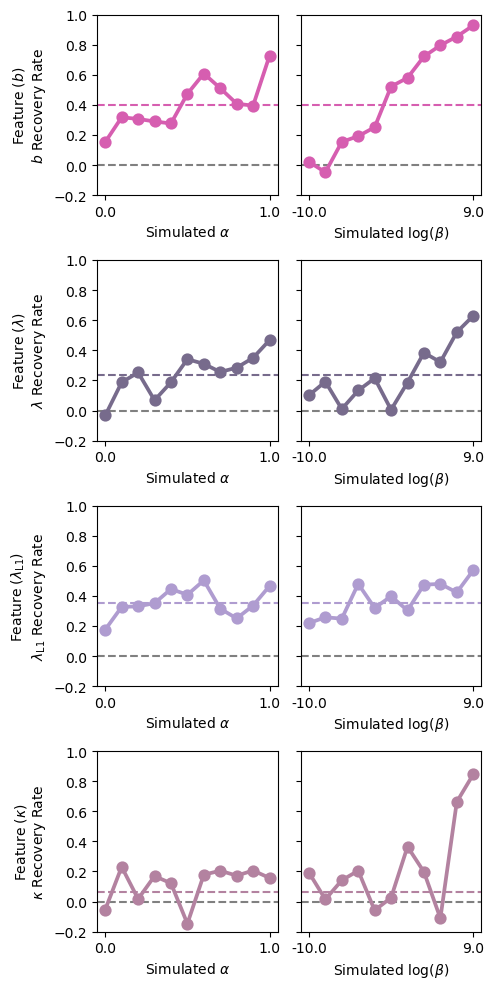

In [36]:
model_param = [
    ('sf-ff-bias', 'bias_magnitude'),
    ('sf-ff-decay', 'lmbd'),
    ('sf-ff-l1reg', 'lmbd_l1'),
    ('sf-ff-nonlin', 'inference_power')
]

fig, axs = plt.subplots(
    len(model_param),
    2,
    figsize = (5, 2.5*len(model_param)),
    sharey = True
    )


for i, (model, target_param) in enumerate(model_param):
    for j, param in enumerate(['alpha_sim', 'beta_trans_sim']):
        ax = axs[i, j]
        ax.axhline(0, color='0.5', linestyle='--')

        idx = (
            (model_fits['model_label_sim'] == model) &
            (model_fits['model_label_fit'] == model)
        )
        plot_df = model_fits.loc[idx, [
            param,
            target_param + '_sim',
            target_param + '_fit'
            ]]

        plot_df[param] = pd.qcut(
            plot_df[param],
            11,
            precision = 2
        )

        unbinned_corr = np.corrcoef(
            plot_df[target_param + '_sim'],
            plot_df[target_param + '_fit']
            )[0, 1]
        ax.axhline(unbinned_corr, c=SF_MODEL_COLORS[model], linestyle='--')

        plot_df['corr'] = np.nan
        for param_bin in plot_df[param].unique():
            idx = (plot_df[param] == param_bin)
            corr = np.corrcoef(
                plot_df.loc[idx, target_param + '_sim'],
                plot_df.loc[idx, target_param + '_fit']
                )[0, 1]
            plot_df.loc[idx, 'corr'] = corr

        plot_df = plot_df[[param, 'corr']].drop_duplicates().sort_values(param)

        sns.pointplot(
            data = plot_df,
            x = param,
            y = 'corr',
            color = SF_MODEL_COLORS[model],
            ci = None,
            ax = ax
        )
        ax.set_xlabel(f'Simulated {PARAM_LABELS[param.replace("_sim", "")]}')
        ax.set_ylabel(MODEL_LABELS[model] + f'\n{PARAM_LABELS[target_param]} Recovery Rate')
        min_max = np.round([model_fits[param].min(), model_fits[param].max()])
        ax.set_xticks([0, 10])
        ax.set_xticklabels(min_max)
        ax.set_ylim(-0.2, 1)
        ax.set_box_aspect(1)

fig.tight_layout()
fig.savefig(
    f'{FIG_PATH}/ff-param-recovery-by-sim-param.pdf',
    bbox_inches = 'tight',
    dpi = 300
    )

In [37]:

MODEL_LABELS = {
    'sf-ff-bias': f'Feature (SF, {PARAM_LABELS["bias_magnitude"]})',
    'mb-ff-bias': f'Feature (MB, {PARAM_LABELS["bias_magnitude"]})'
}


MODEL_LEGLABELS = [v.replace('\n', ' ')  for v in MODEL_LABELS.values()]

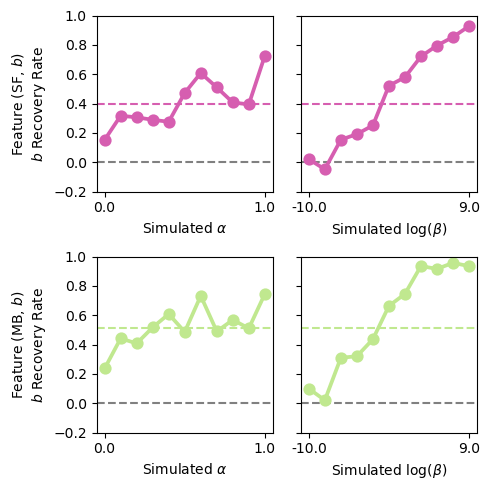

In [38]:
model_param = [
    ('sf-ff-bias', 'bias_magnitude'),
    ('mb-ff-bias', 'bias_magnitude')
]

fig, axs = plt.subplots(
    len(model_param),
    2,
    figsize = (5, 2.5*len(model_param)),
    sharey = True
    )


for i, (model, target_param) in enumerate(model_param):
    model_class = model.split('-')[0]
    for j, param in enumerate(['alpha_sim', 'beta_trans_sim']):
        ax = axs[i, j]
        ax.axhline(0, color='0.5', linestyle='--')

        idx = (
            (model_fits['model_label_sim'] == model) &
            (model_fits['model_label_fit'] == model)
        )
        plot_df = model_fits.loc[idx, [
            param,
            target_param + '_sim',
            target_param + '_fit'
            ]]

        plot_df[param] = pd.qcut(
            plot_df[param],
            11,
            precision = 2
        )

        unbinned_corr = np.corrcoef(
            plot_df[target_param + '_sim'],
            plot_df[target_param + '_fit']
            )[0, 1]
        ax.axhline(unbinned_corr, c=SF_MB_MODEL_COLORS[model_class], linestyle='--')

        plot_df['corr'] = np.nan
        for param_bin in plot_df[param].unique():
            idx = (plot_df[param] == param_bin)
            corr = np.corrcoef(
                plot_df.loc[idx, target_param + '_sim'],
                plot_df.loc[idx, target_param + '_fit']
                )[0, 1]
            plot_df.loc[idx, 'corr'] = corr

        plot_df = plot_df[[param, 'corr']].drop_duplicates().sort_values(param)

        sns.pointplot(
            data = plot_df,
            x = param,
            y = 'corr',
            color = SF_MB_MODEL_COLORS[model_class],
            ci = None,
            ax = ax
        )
        ax.set_xlabel(f'Simulated {PARAM_LABELS[param.replace("_sim", "")]}')
        ax.set_ylabel(MODEL_LABELS[model] + f'\n{PARAM_LABELS[target_param]} Recovery Rate')
        min_max = np.round([model_fits[param].min(), model_fits[param].max()])
        ax.set_xticks([0, 10])
        ax.set_xticklabels(min_max)
        ax.set_ylim(-0.2, 1)
        ax.set_box_aspect(1)

fig.tight_layout()
fig.savefig(
    f'{FIG_PATH}/ff-bias-recovery-by-sim-param.pdf',
    bbox_inches = 'tight',
    dpi = 300
    )

# Compare bias model to decay, regularization, and non-linear inference models

In [72]:
MODEL_COLORS = {
    'sf-ff-bias': '#FF2442',
    'sf-ff-decay': "#821547",
    'sf-ff-l1reg': "#E13505",
    'sf-ff-nonlin': "#A4287B",
    'null': 'grey'
}

MODEL_LABELS = {
    'sf-ff-bias': f'Feature\n({PARAM_LABELS["bias_magnitude"]})',
    'sf-ff-decay': f'Feature\n({PARAM_LABELS["lmbd"]})',
    'sf-ff-l1reg': f'Feature\n({PARAM_LABELS["lmbd_l1"]})',
    'sf-ff-nonlin': f'Feature\n({PARAM_LABELS["inference_power"]})',
    'null': 'Null'
}

MODEL_LEGLABELS = [v.replace('\n', ' ')  for v in MODEL_LABELS.values()]

In [73]:
# Run model comparison within the original models of interest only
#moi = list(MODEL_LABELS.keys())#[:-1]  
moi = list(MODEL_LABELS.keys())[:-1]  
idx = (
    model_fits['model_label_sim'].isin(moi) &
    model_fits['model_label_fit'].isin([*moi, 'null'])
)
model_comparison, best_fits = compare_models(
    model_fits.loc[idx],
    params = [
        'alpha_sim',
        'beta_trans_sim',
        'bias_magnitude_sim',
        'lmbd_sim',
        'lmbd_l1_sim',
        'inference_power_sim'
        ]
    )

best_fits

,id,model_label_sim,model_label_fit,aic,alpha_sim,beta_trans_sim,bias_magnitude_sim,lmbd_sim,lmbd_l1_sim,inference_power_sim,aic_min,best_fit,recovered
0,388,sf-ff-decay,null,881.683214,0.335038,-0.016517,0.000000,0.630919,0.0,1.0,881.683214,1,0
1,363,sf-ff-decay,null,526.791857,0.105407,-0.895927,0.000000,0.562904,0.0,1.0,526.791857,1,0
2,405,sf-ff-decay,sf-ff-nonlin,814.399839,0.701583,0.953040,0.000000,0.187203,0.0,1.0,814.399839,1,0
3,411,sf-ff-decay,sf-ff-l1reg,871.190915,0.845361,-0.484730,0.000000,0.264607,0.0,1.0,871.190915,1,0
4,377,sf-ff-decay,null,881.683214,0.118484,-0.083845,0.000000,0.521873,0.0,1.0,881.683214,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,420,sf-ff-bias,sf-ff-bias,854.657822,0.315646,0.188433,0.266982,0.000000,0.0,1.0,854.657822,1,1
3996,346,sf-ff-bias,sf-ff-bias,119.675833,0.593620,4.690089,0.185610,0.000000,0.0,1.0,119.675833,1,1
3997,408,sf-ff-bias,sf-ff-bias,880.788152,0.493644,-1.600572,0.987027,0.000000,0.0,1.0,880.788152,1,1
3998,391,sf-ff-bias,sf-ff-bias,803.702442,0.058556,1.947487,0.354673,0.000000,0.0,1.0,803.702442,1,1


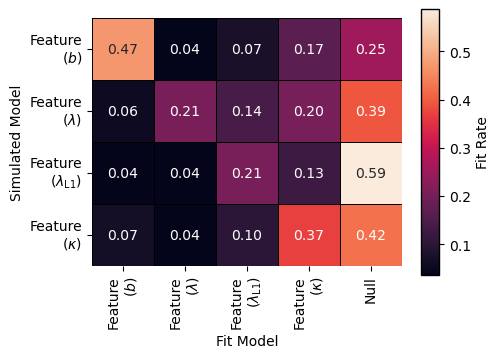

In [74]:
# 1. Compute exact within-group fractions
# Group by the x-axis category AND the hue category
counts_df = (
    best_fits.groupby(['model_label_sim', 'model_label_fit'])
    .size()
    .reset_index(name='count')
)

# Divide each fit count by the total number of simulations for that specific x-axis model
counts_df['fit_rate'] = counts_df['count']/counts_df.groupby('model_label_sim')['count'].transform('sum')


# Plot fits as a heatmap with null as the last column
heatmap_data = counts_df.pivot(
    index='model_label_sim',
    columns='model_label_fit',
    values='fit_rate'
).reindex(index=moi, columns=[*moi, 'null'])  

fig, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(
    heatmap_data,
    annot = True,
    fmt = ".2f",
    cmap = "rocket",
    cbar_kws = {'label': 'Fit Rate', "shrink": 0.69, "aspect": 15},
    linewidths = 0.5,
    linecolor = 'black',
    square = True,
    ax = ax
)

ax.collections[0].colorbar.ax.spines["outline"].set(
    visible=True, edgecolor="black", linewidth=1
)

ax.set_xlabel('Fit Model')
ax.set_ylabel('Simulated Model')
ax.set_xticklabels(MODEL_LABELS.values(), rotation=90,  rotation_mode='anchor', ha='right',  # Centers the vertical text column horizontally on the tick
    va='center')
ax.set_yticklabels(list(MODEL_LABELS.values())[:-1], rotation=0)

fig.savefig(
    f'{FIG_PATH}/ff-alternatives-model-recovery.pdf',
    bbox_inches = 'tight',
    dpi = 300
    )

In [54]:
MODEL_LABELS = {
    'sf-ff-bias': f'Feature ({PARAM_LABELS["bias_magnitude"]})',
    'sf-ff-decay': f'Feature ({PARAM_LABELS["lmbd"]})',
    'sf-ff-l1reg': f'Feature ({PARAM_LABELS["lmbd_l1"]})',
    'sf-ff-nonlin': f'Feature ({PARAM_LABELS["inference_power"]})',
    #'null': 'Null'
}

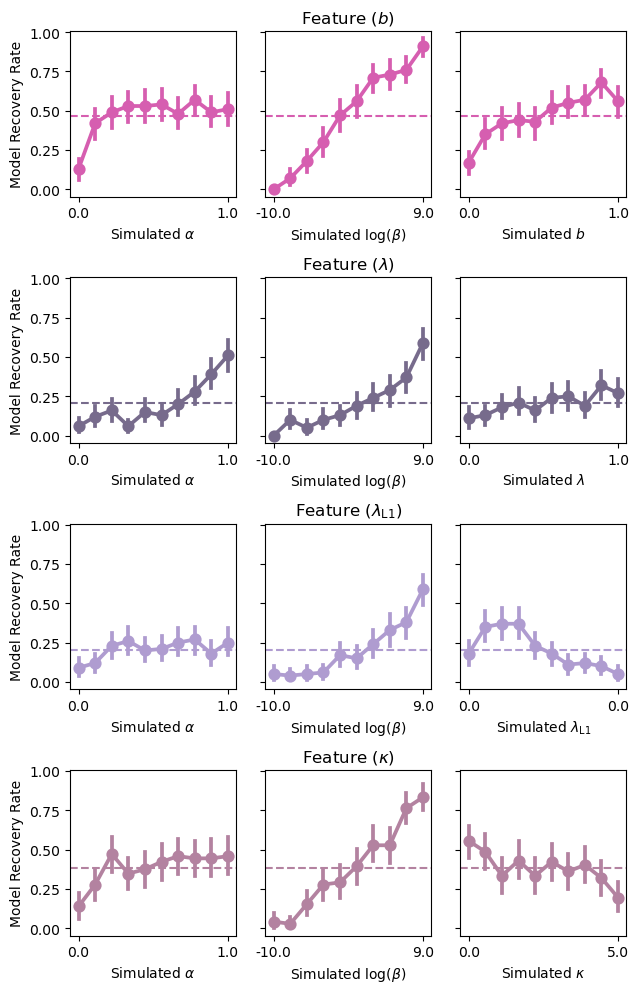

In [55]:
model_param = [
    ('sf-ff-bias', 'bias_magnitude_sim'),
    ('sf-ff-decay', 'lmbd_sim'),
    ('sf-ff-l1reg', 'lmbd_l1_sim'),
    ('sf-ff-nonlin', 'inference_power_sim')
]

fig, axs = plt.subplots(
    len(model_param),
    3,
    figsize = (6.5, 2.5*len(model_param)),
    sharey = True
    )


for i, (model, param) in enumerate(model_param):

    idx = best_fits['model_label_sim'] == model
    
    for j, param in enumerate(['alpha_sim', 'beta_trans_sim', param]):
        ax = axs[i, j]
        plot_df = best_fits.loc[idx, [param, 'recovered']]

        unbinned_recovery = np.mean(plot_df['recovered'])
        ax.axhline(unbinned_recovery, c=SF_MODEL_COLORS[model], linestyle='--')

        plot_df[param] = pd.qcut(
            plot_df[param],
            10,
            precision = 2
            )    

        sns.pointplot(
            data = plot_df,
            x = param,
            y = 'recovered',
            color = SF_MODEL_COLORS[model],
            ax = ax
        )

        # Only keep first and last ticks
        ax.set_xticks([0, 9])
        min_max = np.round([best_fits[param].min(), best_fits[param].max()])
        ax.set_xticklabels(min_max)
        ax.set_xlabel(f'Simulated {PARAM_LABELS[param.replace("_sim", "")]}')
        ax.set_ylabel('Model Recovery Rate') 
        ax.set_box_aspect(1)

    axs[i, 1].set_title(MODEL_LABELS[model], loc='center', fontsize=12)

fig.tight_layout()
fig.savefig(
    f'{FIG_PATH}/ff-model-recovery-by-sim-param.pdf',
    bbox_inches = 'tight',
    dpi = 300
    )

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    lmbd_sim vs bias_magnitude_fit
    Pearson's correlation: 0.02 (p <= 0.5555)
    Spearman's correlation: -0.06 (p <= 0.07)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    lmbd_l1_sim vs bias_magnitude_fit
    Pearson's correlation: 0.1 (p <= 0.001)
    Spearman's correlation: 0.04 (p <= 0.2431)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    inference_power_sim vs bias_magnitude_fit
    Pearson's correlation: 0.07 (p <= 0.056)
    Spearman's correlation: -0.0 (p <= 0.9805)
    


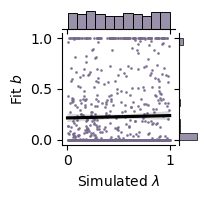

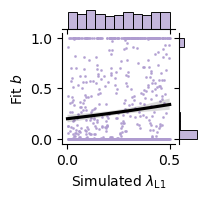

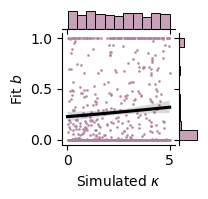

In [42]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-decay') &
    (model_fits['model_label_fit'] == 'sf-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd"]}',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = SF_MODEL_COLORS['sf-ff-decay'],
    fname = f'{FIG_PATH}/sf-ff-bias-decay-sim-vs-bias-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-l1reg') &
    (model_fits['model_label_fit'] == 'sf-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_l1_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd_l1"]}',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = SF_MODEL_COLORS['sf-ff-l1reg'],
    fname = f'{FIG_PATH}/sf-ff-bias-l1reg-sim-vs-bias-bias-fit.pdf'
)


idx = (
    (model_fits['model_label_sim'] == 'sf-ff-nonlin') &
    (model_fits['model_label_fit'] == 'sf-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'inference_power_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["inference_power"]}',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = SF_MODEL_COLORS['sf-ff-nonlin'],
    fname = f'{FIG_PATH}/sf-ff-bias-sim-vs-bias-fit.pdf'
)


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs lmbd_fit
    Pearson's correlation: -0.1 (p <= 0.0011)
    Spearman's correlation: -0.15 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs lmbd_l1_trans_fit
    Pearson's correlation: 0.19 (p <= 0.0001)
    Spearman's correlation: 0.24 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs inference_power_trans_fit
    Pearson's correlation: -0.06 (p <= 0.0437)
    Spearman's correlation: -0.12 (p <= 0.0002)
    


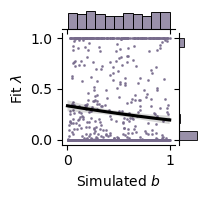

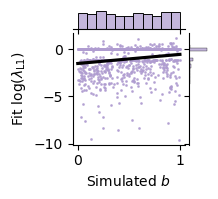

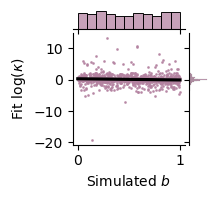

In [43]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias') &
    (model_fits['model_label_fit'] == 'sf-ff-decay')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'lmbd_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}',
    y_label = f'Fit {PARAM_LABELS["lmbd"]}',
    color = SF_MODEL_COLORS['sf-ff-decay'],
    fname = f'{FIG_PATH}/sf-ff-bias-bias-sim-vs-bias-decay-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias') &
    (model_fits['model_label_fit'] == 'sf-ff-l1reg')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'lmbd_l1_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}',
    y_label = f'Fit {PARAM_LABELS["lmbd_l1_trans"]}',
    color = SF_MODEL_COLORS['sf-ff-l1reg'],
    fname = f'{FIG_PATH}/sf-ff-bias-bias-sim-vs-bias-l1reg-fit.pdf',
    logistic = False
)


idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias') &
    (model_fits['model_label_fit'] == 'sf-ff-nonlin')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'inference_power_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}',
    y_label = f'Fit {PARAM_LABELS["inference_power_trans"]}',
    color = SF_MODEL_COLORS['sf-ff-nonlin'],
    fname = f'{FIG_PATH}/sf-ff-bias-bias-sim-vs-bias-nonlin-fit.pdf',
    logistic = False
)


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.4 (p <= 0.0001)
    Spearman's correlation: 0.37 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    lmbd_sim vs lmbd_fit
    Pearson's correlation: 0.24 (p <= 0.0001)
    Spearman's correlation: 0.22 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    lmbd_l1_trans_sim vs lmbd_l1_trans_fit
    Pearson's correlation: 0.2 (p <= 0.0001)
    Spearman's correlation: 0.31 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    inference_power_trans_sim vs inference_power_trans_fit
    Pearson's correlation: 0.33 (p <= 0.0001)
    Spearman's correlation: 0.35 (p <= 0.0001)
    


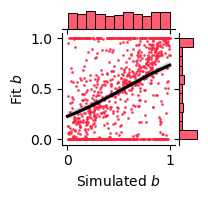

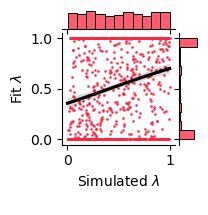

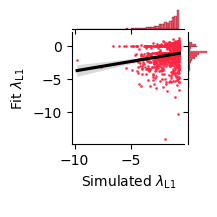

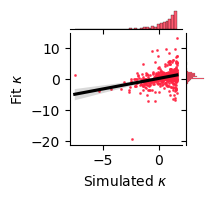

In [23]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias') &
    (model_fits['model_label_fit'] == 'sf-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-decay') &
    (model_fits['model_label_fit'] == 'sf-ff-decay')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_sim',
    'lmbd_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd"]}\n',
    y_label = f'Fit {PARAM_LABELS["lmbd"]}',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-l1reg') &
    (model_fits['model_label_fit'] == 'sf-ff-l1reg')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_l1_trans_sim',
    'lmbd_l1_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd_l1"]}\n',
    y_label = f'Fit {PARAM_LABELS["lmbd_l1"]}',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'\
    logistic = False
)


idx = (
    (model_fits['model_label_sim'] == 'sf-ff-nonlin') &
    (model_fits['model_label_fit'] == 'sf-ff-nonlin')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'inference_power_trans_sim',
    'inference_power_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["inference_power"]}\n',
    y_label = f'Fit {PARAM_LABELS["inference_power"]}',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
    logistic = False
)


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    lmbd_sim vs bias_magnitude_fit
    Pearson's correlation: -0.05 (p <= 0.1196)
    Spearman's correlation: -0.04 (p <= 0.1634)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    lmbd_l1_sim vs bias_magnitude_fit
    Pearson's correlation: -0.05 (p <= 0.1112)
    Spearman's correlation: -0.07 (p <= 0.0234)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    inference_power_sim vs bias_magnitude_fit
    Pearson's correlation: 0.01 (p <= 0.6621)
    Spearman's correlation: -0.0 (p <= 0.9225)
    


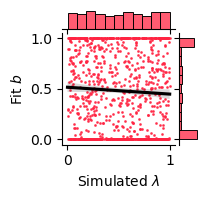

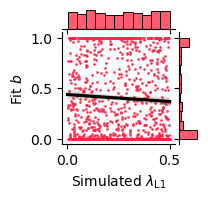

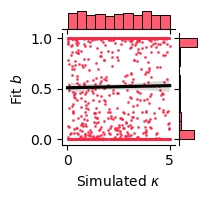

In [341]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-decay') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-decay')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['ff'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-l1reg') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-l1reg')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_l1_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd_l1"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['ff'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)


idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-nonlin') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-nonlin')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'inference_power_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["inference_power"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['ff'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    lmbd_sim vs bias_magnitude_fit
    Pearson's correlation: -0.05 (p <= 0.1196)
    Spearman's correlation: -0.04 (p <= 0.1634)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    lmbd_l1_sim vs bias_magnitude_fit
    Pearson's correlation: -0.05 (p <= 0.1112)
    Spearman's correlation: -0.07 (p <= 0.0234)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    inference_power_sim vs bias_magnitude_fit
    Pearson's correlation: 0.01 (p <= 0.6621)
    Spearman's correlation: -0.0 (p <= 0.9225)
    


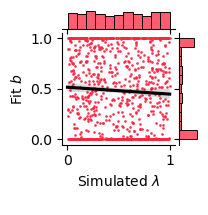

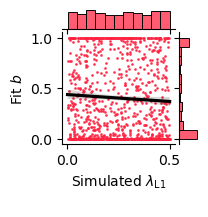

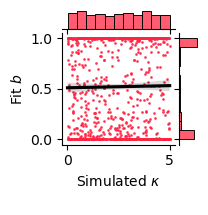

In [23]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-decay') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-decay')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-l1reg') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-l1reg')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_l1_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd_l1"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)


idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-nonlin') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-nonlin')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'inference_power_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["inference_power"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs lmbd_fit
    Pearson's correlation: -0.01 (p <= 0.7453)
    Spearman's correlation: -0.01 (p <= 0.6597)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs lmbd_l1_trans_fit
    Pearson's correlation: -0.03 (p <= 0.2792)
    Spearman's correlation: -0.03 (p <= 0.3731)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs inference_power_trans_fit
    Pearson's correlation: -0.02 (p <= 0.5932)
    Spearman's correlation: -0.02 (p <= 0.5346)
    


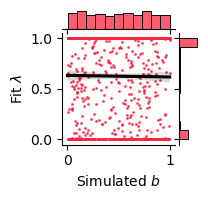

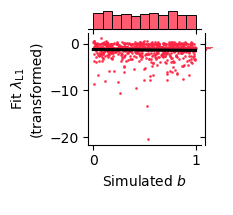

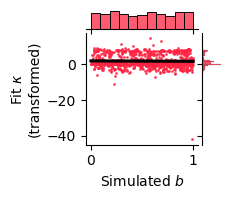

In [21]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-decay') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-decay')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'lmbd_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}\n',
    y_label = f'Fit {PARAM_LABELS["lmbd"]}',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-l1reg') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-l1reg')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'lmbd_l1_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}\n',
    y_label = f'Fit {PARAM_LABELS["lmbd_l1"]}\n(transformed)',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf',
    logistic = False
)


idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-nonlin') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-nonlin')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'inference_power_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}\n',
    y_label = f'Fit {PARAM_LABELS["inference_power"]}\n(transformed)',
    color = MODEL_COLORS['sf-ff-bias'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf',
    logistic = False
)


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.26 (p <= 0.0001)
    Spearman's correlation: 0.24 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    lmbd_sim vs lmbd_fit
    Pearson's correlation: 0.1 (p <= 0.0012)
    Spearman's correlation: 0.07 (p <= 0.0226)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.21 (p <= 0.0001)
    Spearman's correlation: 0.18 (p <= 0.0001)
    


... (2 outputs left out)

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.23 (p <= 0.0001)
    Spearman's correlation: 0.21 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    inference_power_sim vs inference_power_trans_fit
    Pearson's correlation: 0.21 (p <= 0.0001)
    Spearman's correlation: 0.26 (p <= 0.0001)
    


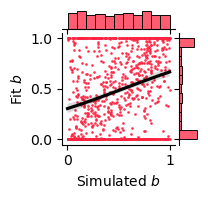

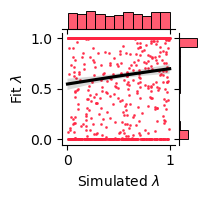

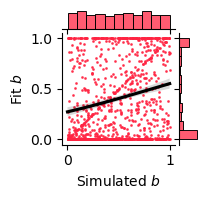

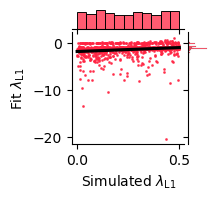

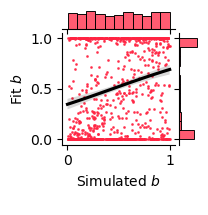

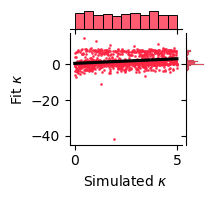

In [343]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-decay') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-decay')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['ff'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-decay') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-decay')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_sim',
    'lmbd_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd"]}\n',
    y_label = f'Fit {PARAM_LABELS["lmbd"]}',
    color = MODEL_COLORS['ff'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-l1reg') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-l1reg')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['ff'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-l1reg') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-l1reg')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'lmbd_l1_sim',
    'lmbd_l1_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["lmbd_l1"]}\n',
    y_label = f'Fit {PARAM_LABELS["lmbd_l1"]}',
    color = MODEL_COLORS['ff'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'\
    logistic = False
)


idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-nonlin') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-nonlin')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]}\n',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]}',
    color = MODEL_COLORS['ff'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias-nonlin') &
    (model_fits['model_label_fit'] == 'sf-ff-bias-nonlin')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'inference_power_sim',
    'inference_power_trans_fit',
    x_label = f'Simulated {PARAM_LABELS["inference_power"]}\n',
    y_label = f'Fit {PARAM_LABELS["inference_power"]}',
    color = MODEL_COLORS['ff'],
    #fname = f'{FIG_PATH}/ff-bias-sim-vs-bias-fit.pdf'
    logistic = False
)


# Comparing successor features and model-based RL

In [10]:
SF_MB_MODEL_COLORS 

{'sf': '#D65EB0', 'mb': '#C0E88F'}

In [46]:
# MODEL_COLORS = {
#     'sf-ss': '#9cd8ff',
#     'mb-ss': "#4b7c9d",
#     'sf-ss-sampler': '#3DB2FF',
#     'mb-ss-sampler': "#0A7FCE",
#     'sf-ff-bias': '#FF2442',
#     'mb-ff-bias': "#A10318",
#     'null': 'grey'
# }

MODEL_LABELS = {
    'sf-ff-bias': 'Feature\n(SF)',
    'mb-ff-bias': 'Feature\n(MB)',
    'sf-ss': 'Conj.\n(SF)',
    'mb-ss': 'Conj.\n(MB)',
    'sf-ss-sampler': 'Conj. Sampler\n(SF)',
    'mb-ss-sampler': 'Conj. Sampler\n(MB)',
    'null': 'Null'
}

MODEL_LEGLABELS = [v.replace('\n', ' ')  for k, v in MODEL_LABELS.items()]

In [67]:
# Run model comparison within the original models of interest only
moi = list(MODEL_LABELS.keys())[:-1]  
idx = (
    model_fits['model_label_sim'].isin(moi) &
    model_fits['model_label_fit'].isin([*moi, 'null'])
)
model_comparison, best_fits = compare_models(model_fits.loc[idx])

best_fits

,id,model_label_sim,model_label_fit,aic,aic_min,best_fit,recovered
0,388,mb-ss,mb-ss,862.924339,862.924339,1,1
1,363,mb-ss,null,881.683214,881.683214,1,0
2,405,mb-ss,mb-ss,667.723694,667.723694,1,1
3,411,mb-ss,mb-ss,863.003388,863.003388,1,1
4,377,mb-ss,mb-ss,880.832496,880.832496,1,1
...,...,...,...,...,...,...,...
5995,420,sf-ss,sf-ss,858.986915,858.986915,1,1
5996,346,sf-ss,sf-ss,440.489117,440.489117,1,1
5997,408,sf-ss,null,881.683214,881.683214,1,0
5998,391,sf-ss,sf-ss,834.705005,834.705005,1,1


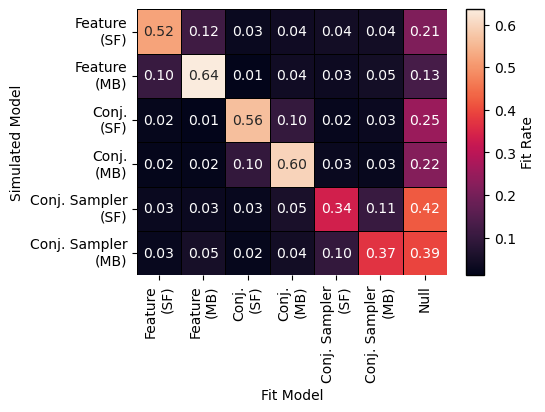

In [71]:
# 1. Compute exact within-group fractions
# Group by the x-axis category AND the hue category
counts_df = (
    best_fits.groupby(['model_label_sim', 'model_label_fit'])
    .size()
    .reset_index(name='count')
)

# Divide each fit count by the total number of simulations for that specific x-axis model
counts_df['fit_rate'] = counts_df['count']/counts_df.groupby('model_label_sim')['count'].transform('sum')


# Plot fits as a heatmap with null as the last column
heatmap_data = counts_df.pivot(
    index='model_label_sim',
    columns='model_label_fit',
    values='fit_rate'
).reindex(index=moi, columns=[*moi, 'null'])  

fig, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(
    heatmap_data,
    annot = True,
    fmt = ".2f",
    cmap = "rocket",
    cbar_kws = {'label': 'Fit Rate', "shrink": 0.69, "aspect": 15},
    linewidths = 0.5,
    linecolor = 'black',
    square=True,
    ax = ax
)

ax.collections[0].colorbar.ax.spines["outline"].set(
    visible=True, edgecolor="black", linewidth=1
)

ax.set_xlabel('Fit Model')
ax.set_ylabel('Simulated Model')
ax.set_xticklabels(MODEL_LABELS.values(), rotation=90,  rotation_mode='anchor', ha='right',  # Centers the vertical text column horizontally on the tick
    va='center')
ax.set_yticklabels(list(MODEL_LABELS.values())[:-1], rotation=0)

fig.savefig(
    f'{FIG_PATH}/sf-mb-model-recovery.pdf',
    bbox_inches = 'tight',
    dpi = 300
    )

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.35 (p <= 0.0001)
    Spearman's correlation: 0.32 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.42 (p <= 0.0001)
    Spearman's correlation: 0.42 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.51 (p <= 0.0001)
    Spearman's correlation: 0.48 (p <= 0.0001)
    


/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/seaborn/axisgrid.py:1766: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  f.tight_layout()



    bias_magnitude_sim vs bias_magnitude_fit
    Pearson's correlation: 0.4 (p <= 0.0001)
    Spearman's correlation: 0.37 (p <= 0.0001)
    


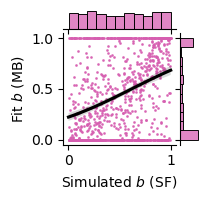

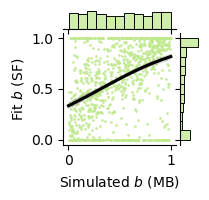

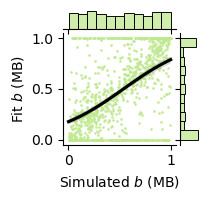

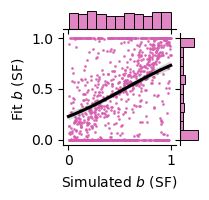

In [69]:
idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias') &
    (model_fits['model_label_fit'] == 'mb-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]} (SF)',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]} (MB)',
    color = SF_MB_MODEL_COLORS['sf'],
    fname = f'{FIG_PATH}/ff-bias-sf-sim-vs-bias-mb-fit.pdf'
)

idx = (
    (model_fits['model_label_sim'] == 'mb-ff-bias') &
    (model_fits['model_label_fit'] == 'sf-ff-bias')
)

plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]} (MB)',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]} (SF)',
    color = SF_MB_MODEL_COLORS['mb'],
    fname = f'{FIG_PATH}/ff-bias-mb-sim-vs-bias-sf-fit.pdf'
)


idx = (
    (model_fits['model_label_sim'] == 'mb-ff-bias') &
    (model_fits['model_label_fit'] == 'mb-ff-bias')
)
plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]} (MB)',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]} (MB)',
    color = SF_MB_MODEL_COLORS['mb'],
    fname = f'{FIG_PATH}/ff-bias-mb-sim-vs-bias-mb-fit.pdf'
)


idx = (
    (model_fits['model_label_sim'] == 'sf-ff-bias') &
    (model_fits['model_label_fit'] == 'sf-ff-bias')
)
plot_parameter_relationship(
    model_fits.loc[idx],
    'bias_magnitude_sim',
    'bias_magnitude_fit',
    x_label = f'Simulated {PARAM_LABELS["bias_magnitude"]} (SF)',
    y_label = f'Fit {PARAM_LABELS["bias_magnitude"]} (SF)',
    color = SF_MB_MODEL_COLORS['sf'],
    fname = f'{FIG_PATH}/ff-bias-sf-sim-vs-bias-sf-fit.pdf'
)

